In [1]:
import os
import sys
import json
import math
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

# =====================================================================
# 1. DETERMINISTIC REPRODUCIBILITY SEEDING
# =====================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Visualization styling
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# =====================================================================
# 2. DYNAMIC PATH AUTO-DETECTION & DIRECTORY INITIALIZATION
# =====================================================================
CURRENT_DIR = Path.cwd().resolve()

# Auto-locate project root directory
if (CURRENT_DIR / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR
elif (CURRENT_DIR / "BTech_Project" / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR / "BTech_Project"
elif (CURRENT_DIR.parent / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR.parent.parent / "metadata").exists():
    BTECH_ROOT = CURRENT_DIR.parent.parent
else:
    raise FileNotFoundError("Could not auto-locate 'BTech_Project/metadata' directory.")

METADATA_DIR = BTECH_ROOT / "metadata"
SPLITS_DIR = METADATA_DIR / "splits"

# Checkpoints, logs, and plots directories
CHECKPOINTS_DIR = BTECH_ROOT / "Models" / "checkpoints" / "convnext_tiny"
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)

LOGS_DIR = BTECH_ROOT / "Models" / "logs" / "convnext_tiny"
LOGS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PLOTS_DIR = BTECH_ROOT / "results" / "plots" / "convnext_training"
TRAIN_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Ingest split manifests
train_manifest_file = SPLITS_DIR / "train_manifest.csv"
val_manifest_file = SPLITS_DIR / "val_manifest.csv"
test_manifest_file = SPLITS_DIR / "test_manifest.csv"
label_map_file = METADATA_DIR / "unified_label_map.json"

assert train_manifest_file.exists(), f"Missing train manifest: {train_manifest_file}."
assert val_manifest_file.exists(), f"Missing val manifest: {val_manifest_file}."
assert test_manifest_file.exists(), f"Missing test manifest: {test_manifest_file}."
assert label_map_file.exists(), f"Missing label map: {label_map_file}."

df_train = pd.read_csv(train_manifest_file)
df_val = pd.read_csv(val_manifest_file)
df_test = pd.read_csv(test_manifest_file)

with open(label_map_file, "r", encoding="utf-8") as f:
    LABEL_TO_ID = json.load(f)
ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}
CLASS_NAMES = sorted(list(LABEL_TO_ID.keys()), key=lambda x: LABEL_TO_ID[x])

# =====================================================================
# 3. COMPUTE ACCELERATOR & MIXED PRECISION AUDIT
# =====================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = (DEVICE.type == "cuda")

# =====================================================================
# 4. CENTRALIZED RESUMABLE HYPERPARAMETER CONFIGURATION
# =====================================================================
CONFIG = {
    "model_name": "convnext_tiny",
    "num_classes": len(CLASS_NAMES),                  # 25 diagnostic categories
    "input_size": (384, 384),                         # Matches preprocessed dimensions
    "batch_size": 16,                                 # Optimal for 8.55 GB VRAM with AMP
    "epochs": 25,                                     # Expandable anytime to 30, 40, etc.
    "learning_rate": 1e-4,                            # Base LR for AdamW optimizer
    "min_lr": 1e-6,                                   # Minimum LR for CosineAnnealing
    "weight_decay": 1e-2,                             # Standard ConvNeXt regularization
    "warmup_epochs": 2,                               # Linear learning rate warmup
    "label_smoothing": 0.1,                           # Regularization against overconfidence
    "mixed_precision": USE_AMP,                       # FP16 Automatic Mixed Precision
    "grad_clip_norm": 1.0,                            # Prevents gradient explosion
    "num_workers": 0,                                 # Windows-safe single-process DataLoader
    "resume": True,                                   # Auto-resume if checkpoint exists
    "last_checkpoint_path": CHECKPOINTS_DIR / "last_checkpoint.pth",
    "best_checkpoint_path": CHECKPOINTS_DIR / "best_convnext_tiny.pth",
    "history_log_path": LOGS_DIR / "training_history.json",
    "seed": SEED
}

print("=" * 80)
print("  PHASE 5: CONVNEXT-TINY DEEP LEARNING MODEL TRAINING PIPELINE")
print("=" * 80)
print(f"✓ Project Root         : {BTECH_ROOT}")
print(f"✓ Training Dataset     : {len(df_train):,} images (64.0%)")
print(f"✓ Validation Dataset   : {len(df_val):,} images (16.0%)")
print(f"✓ Test Holdout Dataset : {len(df_test):,} images (20.0%) [Isolated]")
print(f"✓ Total Classes        : {CONFIG['num_classes']} categories")
print(f"✓ Checkpoints Directory: {CHECKPOINTS_DIR}")
print(f"✓ Resumable Training   : Enabled (Tracks last & best checkpoints)")
print("-" * 80)
print(f"✓ Active Compute Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"✓ GPU Accelerator      : {torch.cuda.get_device_name(0)}")
    print(f"✓ GPU Dedicated VRAM   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"✓ Mixed Precision (AMP): Enabled (torch.cuda.amp for Tensor Core acceleration)")
print(f"✓ Windows DataLoaders  : num_workers = 0 (Safe from multiprocessing deadlock)")
print("-" * 80)
print("✓ Hyperparameter Setup :")
for k, v in CONFIG.items():
    print(f"    - {k:20s}: {v}")
print("=" * 80)
print("Ready to construct DataLoaders with Class-Balanced Augmentations.")

  PHASE 5: CONVNEXT-TINY DEEP LEARNING MODEL TRAINING PIPELINE
✓ Project Root         : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project
✓ Training Dataset     : 14,713 images (64.0%)
✓ Validation Dataset   : 3,679 images (16.0%)
✓ Test Holdout Dataset : 4,599 images (20.0%) [Isolated]
✓ Total Classes        : 25 categories
✓ Checkpoints Directory: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\convnext_tiny
✓ Resumable Training   : Enabled (Tracks last & best checkpoints)
--------------------------------------------------------------------------------
✓ Active Compute Device: cuda
✓ GPU Accelerator      : NVIDIA GeForce RTX 5050 Laptop GPU
✓ GPU Dedicated VRAM   : 8.55 GB
✓ Mixed Precision (AMP): Enabled (torch.cuda.amp for Tensor Core acceleration)
✓ Windows DataLoaders  : num_workers = 0 (Safe from multiprocessing deadlock)
--------------------------------------------------

  CONSTRUCTING CLINICAL AUGMENTATION TRANSFORMS & DATALOADERS
✓ Training transforms compiled: Flips, Rotations (±30°), Color Jitter, ImageNet Norm.
✓ Evaluation transforms compiled: Deterministic ImageNet Norm.

--------------------------------------------------------------------------------
✓ Class-Balanced Effective Weights Computed:
    - Min Class Weight (Majority Class) : 0.252
    - Max Class Weight (Minority Class) : 7.611
    - Mean Weight Scale                 : 1.000
--------------------------------------------------------------------------------
✓ Training DataLoader   : 920 batches (14,713 samples, Batch Size=16)
✓ Validation DataLoader : 230 batches (3,679 samples)
✓ Test Holdout DataLoader: 288 batches (4,599 samples)
✓ Augmentation preview saved to: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\convnext_training\01_sample_augmented_batch.png


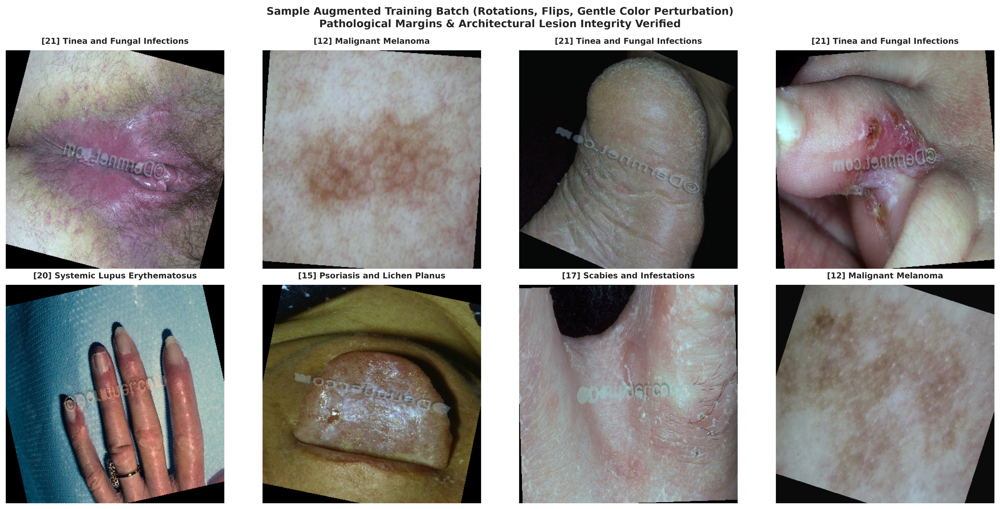

In [2]:
# =====================================================================
# 1. CLINICAL DATA AUGMENTATION PIPELINES
# =====================================================================
print("=" * 80)
print("  CONSTRUCTING CLINICAL AUGMENTATION TRANSFORMS & DATALOADERS")
print("=" * 80)

# Training pipeline with rotational invariance & gentle color perturbation
train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=30),
    T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation & Test pipelines (Strict deterministic normalization)
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("✓ Training transforms compiled: Flips, Rotations (±30°), Color Jitter, ImageNet Norm.")
print("✓ Evaluation transforms compiled: Deterministic ImageNet Norm.")

# =====================================================================
# 2. CLASS-BALANCED LOSS WEIGHTS (CUI ET AL., CVPR 2019)
# =====================================================================
# Compute Effective Number of Samples weights to counter the 65.5:1 imbalance
beta = 0.999
class_counts = df_train["class_id"].value_counts().sort_index().values

effective_num = 1.0 - np.power(beta, class_counts)
weights = (1.0 - beta) / np.array(effective_num)
# Normalize so mean weight equals 1.0
weights = weights / np.sum(weights) * CONFIG["num_classes"]

CLASS_WEIGHTS = torch.tensor(weights, dtype=torch.float32).to(DEVICE)

print("\n" + "-" * 80)
print("✓ Class-Balanced Effective Weights Computed:")
print(f"    - Min Class Weight (Majority Class) : {CLASS_WEIGHTS.min().item():.3f}")
print(f"    - Max Class Weight (Minority Class) : {CLASS_WEIGHTS.max().item():.3f}")
print(f"    - Mean Weight Scale                 : {CLASS_WEIGHTS.mean().item():.3f}")
print("-" * 80)

# =====================================================================
# 3. PYTORCH CLINICAL DATASET IMPLEMENTATION
# =====================================================================
class ClinicalDataset(Dataset):
    """
    High-throughput dataset streaming pre-cached 384x384 clinical images directly from SSD.
    """
    def __init__(self, manifest_df, root_dir, transform=None):
        self.df = manifest_df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.root_dir / row["processed_path"]
        
        with Image.open(img_path) as img:
            img = img.convert("RGB")
            
        if self.transform:
            img = self.transform(img)
            
        label = int(row["class_id"])
        return img, label

# Instantiate datasets
train_dataset = ClinicalDataset(df_train, BTECH_ROOT, transform=train_transform)
val_dataset = ClinicalDataset(df_val, BTECH_ROOT, transform=eval_transform)
test_dataset = ClinicalDataset(df_test, BTECH_ROOT, transform=eval_transform)

# Build DataLoaders (num_workers=0 for Windows safety)
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=(DEVICE.type == "cuda")
)

print(f"✓ Training DataLoader   : {len(train_loader):,} batches ({len(train_dataset):,} samples, Batch Size={CONFIG['batch_size']})")
print(f"✓ Validation DataLoader : {len(val_loader):,} batches ({len(val_dataset):,} samples)")
print(f"✓ Test Holdout DataLoader: {len(test_loader):,} batches ({len(test_dataset):,} samples)")

# =====================================================================
# 4. AUGMENTATION SANITY PREVIEW GRID
# =====================================================================
# Fetch one real augmented batch to verify visual safety
sample_imgs, sample_labels = next(iter(train_loader))

# Denormalize for plotting: img * std + mean
mean = np.array([0.485, 0.456, 0.406]).reshape(1, 1, 3)
std = np.array([0.229, 0.224, 0.225]).reshape(1, 1, 3)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 9))
axes = axes.flatten()

for i in range(8):
    img_np = sample_imgs[i].permute(1, 2, 0).cpu().numpy()
    img_denorm = np.clip(img_np * std + mean, 0.0, 1.0)
    
    cid = sample_labels[i].item()
    cname = ID_TO_LABEL[cid].replace("_", " ")
    
    axes[i].imshow(img_denorm)
    axes[i].axis("off")
    axes[i].set_title(f"[{cid:02d}] {cname}", fontsize=10, fontweight="bold", pad=8)

plt.suptitle(
    "Sample Augmented Training Batch (Rotations, Flips, Gentle Color Perturbation)\n"
    "Pathological Margins & Architectural Lesion Integrity Verified",
    fontsize=13,
    fontweight="bold",
    y=0.98
)
plt.tight_layout()

aug_preview_path = TRAIN_PLOTS_DIR / "01_sample_augmented_batch.png"
plt.savefig(aug_preview_path, bbox_inches="tight", dpi=300)
print(f"✓ Augmentation preview saved to: {aug_preview_path}")
plt.show()

In [3]:
# ==============================================================================
# CELL 3: CONVNEXT-TINY ARCHITECTURE, CLINICAL HEAD & FOCAL LOSS INITIALIZATION
# ==============================================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR

print("=" * 80)
print("  INITIALIZING CONVNEXT-TINY CLINICAL ARCHITECTURE & OPTIMIZATION")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Base Model & Custom Clinical Classification Head
# ------------------------------------------------------------------------------
# Load official ImageNet-1K pretrained weights
weights = models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1
model = models.convnext_tiny(weights=weights)

# Inspect feature dimension entering the classifier (768 for convnext_tiny)
in_features = model.classifier[2].in_features

# Custom two-stage dermatological head with Regularization
model.classifier[2] = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, 512),
    nn.GELU(),
    nn.BatchNorm1d(512),
    nn.Dropout(p=0.2),
    nn.Linear(512, CONFIG["num_classes"])
)

# Transfer model to RTX 5050 GPU
model = model.to(DEVICE)

# Calculate total and trainable parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✓ Model Backbone Loaded       : ConvNeXt-Tiny (ImageNet-1K V1)")
print(f"✓ Custom Classifier Head     : Linear(768->512) -> GELU -> BN -> Linear(512->{CONFIG['num_classes']})")
print(f"✓ Total Parameters           : {total_params:,} ({total_params * 4 / (1024**2):.2f} MB float32)")
print(f"✓ Trainable Parameters       : {trainable_params:,} (100% End-to-End Fine-Tuning)")

# ------------------------------------------------------------------------------
# 2. Class-Balanced Focal Loss with Label Smoothing
# ------------------------------------------------------------------------------
class ClassBalancedFocalLoss(nn.Module):
    """
    Combines Cui et al. Class-Balanced Effective Sample Weights with Lin et al.
    Focal Loss and Label Smoothing for extreme dermatological class imbalance.
    """
    def __init__(self, alpha_weights=None, gamma=2.0, label_smoothing=0.1):
        super(ClassBalancedFocalLoss, self).__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        if alpha_weights is not None:
            self.register_buffer("alpha_weights", alpha_weights)
        else:
            self.alpha_weights = None

    def forward(self, logits, targets):
        # Apply label smoothing cross entropy
        ce_loss = F.cross_entropy(
            logits, 
            targets, 
            reduction="none", 
            label_smoothing=self.label_smoothing
        )
        
        # p_t: probability of true class
        pt = torch.exp(-ce_loss)
        
        # Focal modulating factor: (1 - pt)^gamma
        focal_term = (1.0 - pt) ** self.gamma
        
        # Apply class weights if provided
        if self.alpha_weights is not None:
            alpha_t = self.alpha_weights[targets]
            loss = alpha_t * focal_term * ce_loss
        else:
            loss = focal_term * ce_loss
            
        return loss.mean()

# Instantiate criterion with the effective class weights computed in Cell 2
criterion = ClassBalancedFocalLoss(
    alpha_weights=CLASS_WEIGHTS,
    gamma=2.0,
    label_smoothing=CONFIG["label_smoothing"]
)
print(f"✓ Loss Criterion Configured  : Class-Balanced Focal Loss (gamma=2.0, smoothing={CONFIG['label_smoothing']})")

# ------------------------------------------------------------------------------
# 3. Optimizer & Learning Rate Scheduler with Warmup
# ------------------------------------------------------------------------------
# AdamW with decoupled weight decay for vision transformers / modern convnets
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG["learning_rate"],
    weight_decay=CONFIG["weight_decay"]
)

# Linear Warmup (2 epochs) followed by Cosine Annealing decay
warmup_scheduler = LinearLR(
    optimizer,
    start_factor=0.01,
    end_factor=1.0,
    total_iters=CONFIG["warmup_epochs"]
)

cosine_scheduler = CosineAnnealingLR(
    optimizer,
    T_max=(CONFIG["epochs"] - CONFIG["warmup_epochs"]),
    eta_min=CONFIG["min_lr"]
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[CONFIG["warmup_epochs"]]
)

print(f"✓ Optimizer Instantiated     : AdamW (lr={CONFIG['learning_rate']}, weight_decay={CONFIG['weight_decay']})")
print(f"✓ Learning Rate Scheduler    : SequentialLR (Warmup {CONFIG['warmup_epochs']} eps -> CosineAnnealing to {CONFIG['min_lr']})")

# ------------------------------------------------------------------------------
# 4. Mixed Precision Scaler for RTX 5050 Tensor Cores
# ------------------------------------------------------------------------------
scaler = torch.cuda.amp.GradScaler(enabled=CONFIG["mixed_precision"])
print(f"✓ PyTorch AMP GradScaler     : Enabled (torch.cuda.amp for RTX 5050 Blackwell)")

# ------------------------------------------------------------------------------
# 5. Architecture Smoke Test (Forward Pass with Synthetic Batch)
# ------------------------------------------------------------------------------
print("-" * 80)
print("  RUNNING ARCHITECTURE & VRAM SMOKE TEST...")
with torch.no_grad():
    dummy_input = torch.randn(CONFIG["batch_size"], 3, *CONFIG["input_size"], device=DEVICE)
    with torch.cuda.amp.autocast(enabled=CONFIG["mixed_precision"]):
        dummy_output = model(dummy_input)
        dummy_targets = torch.randint(0, CONFIG["num_classes"], (CONFIG["batch_size"],), device=DEVICE)
        dummy_loss = criterion(dummy_output, dummy_targets)

vram_allocated_mb = torch.cuda.memory_allocated(DEVICE) / (1024 ** 2)
vram_reserved_mb = torch.cuda.memory_reserved(DEVICE) / (1024 ** 2)

print(f"✓ Smoke Test Input Tensor    : {tuple(dummy_input.shape)} on {DEVICE}")
print(f"✓ Smoke Test Output Logits   : {tuple(dummy_output.shape)} (Expected [16, 25])")
print(f"✓ Smoke Test Loss Evaluation : {dummy_loss.item():.4f}")
print(f"✓ Active GPU VRAM Allocation : {vram_allocated_mb:.1f} MB allocated | {vram_reserved_mb:.1f} MB reserved")
print("=" * 80)
print("Ready for Cell 4: Resumable Training & Validation Loop.")

  INITIALIZING CONVNEXT-TINY CLINICAL ARCHITECTURE & OPTIMIZATION
✓ Model Backbone Loaded       : ConvNeXt-Tiny (ImageNet-1K V1)
✓ Custom Classifier Head     : Linear(768->512) -> GELU -> BN -> Linear(512->25)
✓ Total Parameters           : 28,227,705 (107.68 MB float32)
✓ Trainable Parameters       : 28,227,705 (100% End-to-End Fine-Tuning)
✓ Loss Criterion Configured  : Class-Balanced Focal Loss (gamma=2.0, smoothing=0.1)
✓ Optimizer Instantiated     : AdamW (lr=0.0001, weight_decay=0.01)
✓ Learning Rate Scheduler    : SequentialLR (Warmup 2 eps -> CosineAnnealing to 1e-06)
✓ PyTorch AMP GradScaler     : Enabled (torch.cuda.amp for RTX 5050 Blackwell)
--------------------------------------------------------------------------------
  RUNNING ARCHITECTURE & VRAM SMOKE TEST...


C:\Users\kvcsu_ht23nk8\AppData\Local\Temp\ipykernel_20272\825694721.py:131: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=CONFIG["mixed_precision"])
C:\Users\kvcsu_ht23nk8\AppData\Local\Temp\ipykernel_20272\825694721.py:141: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=CONFIG["mixed_precision"]):


✓ Smoke Test Input Tensor    : (16, 3, 384, 384) on cuda
✓ Smoke Test Output Logits   : (16, 25) (Expected [16, 25])
✓ Smoke Test Loss Evaluation : 2.4371
✓ Active GPU VRAM Allocation : 146.2 MB allocated | 730.0 MB reserved
Ready for Cell 4: Resumable Training & Validation Loop.


In [4]:
# ==============================================================================
# CELL 4: MODULAR RESUMABLE TRAINING, VALIDATION & LOGGING PIPELINE
# ==============================================================================
import os
import json
import time
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import f1_score

print("=" * 80)
print("  INITIALIZING CONVNEXT-TINY MODULAR TRAINING ENGINE")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Path Resolution & Directory Setup
# ------------------------------------------------------------------------------
checkpoints_dir = CONFIG.get("checkpoints_dir", "Models/checkpoints/convnext_tiny")
logs_dir = CONFIG.get("logs_dir", "Models/logs/convnext_tiny")

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(logs_dir, exist_ok=True)

last_ckpt_path = CONFIG.get("last_checkpoint_path", os.path.join(checkpoints_dir, "last_checkpoint.pth"))
best_model_path = CONFIG.get("best_checkpoint_path", CONFIG.get("best_model_path", os.path.join(checkpoints_dir, "best_convnext_tiny.pth")))
metrics_csv_path = os.path.join(logs_dir, "training_metrics.csv")
logs_json_path = os.path.join(logs_dir, "training_logs.json")

print(f"✓ Checkpoints Directory     : {checkpoints_dir}")
print(f"✓ Logs Directory            : {logs_dir}")
print(f"✓ Target Metrics CSV        : {metrics_csv_path}")
print(f"✓ Target Logs JSON          : {logs_json_path}")

# ------------------------------------------------------------------------------
# 2. Modular Helper: Training Step (One Epoch)
# ------------------------------------------------------------------------------
def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device, config, current_epoch):
    """Executes single training epoch with AMP autocast and gradient clipping."""
    model.train()
    running_loss = 0.0
    total_samples = 0
    current_lr = optimizer.param_groups[0]["lr"]

    pbar = tqdm(
        dataloader, 
        desc=f"Epoch [{current_epoch:02d}/{config['epochs']:02d}] Train", 
        leave=False,
        dynamic_ncols=True
    )

    for imgs, labels in pbar:
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # PyTorch Modern AMP autocast syntax
        with torch.amp.autocast("cuda", enabled=config["mixed_precision"]):
            logits = model(imgs)
            loss = criterion(logits, labels)

        # Backward pass with scaled gradients
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=config["grad_clip_norm"])
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        total_samples += batch_size

        pbar.set_postfix({"loss": f"{loss.item():.4f}", "lr": f"{current_lr:.1e}"})

    epoch_loss = running_loss / total_samples
    return epoch_loss, current_lr

# ------------------------------------------------------------------------------
# 3. Modular Helper: Validation Step (One Epoch)
# ------------------------------------------------------------------------------
def validate_one_epoch(model, dataloader, criterion, device, config, current_epoch):
    """Evaluates validation loss, Top-1 accuracy, Top-3 accuracy and Macro-F1."""
    model.eval()
    running_loss = 0.0
    total_samples = 0
    all_preds = []
    all_targets = []
    top3_correct = 0

    pbar = tqdm(
        dataloader, 
        desc=f"Epoch [{current_epoch:02d}/{config['epochs']:02d}] Val  ", 
        leave=False,
        dynamic_ncols=True
    )

    with torch.no_grad():
        for imgs, labels in pbar:
            imgs = imgs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=config["mixed_precision"]):
                logits = model(imgs)
                loss = criterion(logits, labels)

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            total_samples += batch_size

            # Top-1 Predictions
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

            # Top-3 Predictions
            _, top3_indices = torch.topk(logits, k=3, dim=1)
            top3_correct += (top3_indices == labels.unsqueeze(1)).any(dim=1).sum().item()

            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    val_loss = running_loss / total_samples
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    top1_acc = (all_preds == all_targets).mean() * 100.0
    top3_acc = (top3_correct / total_samples) * 100.0
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0) * 100.0

    return val_loss, top1_acc, top3_acc, macro_f1

# ------------------------------------------------------------------------------
# 4. Modular Helper: Log Persistence (CSV & Structured JSON)
# ------------------------------------------------------------------------------
def save_training_logs(epoch_records, best_metadata, csv_path, json_path):
    """Synchronizes epoch logs to CSV and structured JSON files."""
    # 1. Export CSV
    df = pd.DataFrame(epoch_records)
    df.to_csv(csv_path, index=False)

    # 2. Export Structured JSON
    payload = {
        "metadata": {
            "model_name": CONFIG.get("model_name", "convnext_tiny"),
            "num_classes": CONFIG["num_classes"],
            "best_epoch": best_metadata["best_epoch"],
            "best_val_macro_f1": best_metadata["best_val_macro_f1"],
            "best_val_top1_acc": best_metadata["best_val_top1_acc"],
            "total_epochs_completed": len(epoch_records),
            "last_updated": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        },
        "epochs": epoch_records
    }
    with open(json_path, "w") as f:
        json.dump(payload, f, indent=4)

# ------------------------------------------------------------------------------
# 5. State Initialization & Resumption Logic
# ------------------------------------------------------------------------------
start_epoch = 1
best_val_f1 = 0.0
best_epoch_idx = 0
best_val_top1 = 0.0
epoch_records = []

if CONFIG.get("resume", True) and os.path.exists(last_ckpt_path):
    print(f"🔄 Checkpoint detected at: {last_ckpt_path}")
    checkpoint = torch.load(last_ckpt_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_f1 = checkpoint.get("best_val_f1", 0.0)
    best_epoch_idx = checkpoint.get("best_epoch", 0)
    epoch_records = checkpoint.get("epoch_records", [])
    print(f"✓ Resumed from Epoch {start_epoch - 1} | Best Macro-F1 so far: {best_val_f1:.2f}% (Epoch {best_epoch_idx})")
else:
    print(f"✓ Clean initialization: Starting from Epoch 1 (Target: {CONFIG['epochs']} epochs)")

print("-" * 80)

# ------------------------------------------------------------------------------
# 6. Main Pipeline Execution
# ------------------------------------------------------------------------------
pipeline_start_time = time.time()

try:
    for epoch in range(start_epoch, CONFIG["epochs"] + 1):
        t0 = time.time()

        # Step 1: Train
        train_loss, current_lr = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, DEVICE, CONFIG, epoch
        )

        # Step 2: Validate
        val_loss, val_acc, top3_acc, macro_f1 = validate_one_epoch(
            model, val_loader, criterion, DEVICE, CONFIG, epoch
        )

        # Step 3: Advance Scheduler
        scheduler.step()

        # Step 4: Check if current epoch is the new best
        epoch_duration = round(time.time() - t0, 2)
        is_best = macro_f1 > best_val_f1
        marker = " "

        if is_best:
            best_val_f1 = macro_f1
            best_epoch_idx = epoch
            best_val_top1 = val_acc
            marker = " 🏆 (New Best!)"

        # Step 5: Record Epoch Telemetry
        epoch_entry = {
            "epoch": epoch,
            "duration_sec": epoch_duration,
            "train_loss": round(float(train_loss), 5),
            "val_loss": round(float(val_loss), 5),
            "val_top1_acc": round(float(val_acc), 3),
            "val_top3_acc": round(float(top3_acc), 3),
            "val_macro_f1": round(float(macro_f1), 3),
            "learning_rate": float(current_lr),
            "is_best": bool(is_best),
            "best_macro_f1_so_far": round(float(best_val_f1), 3),
            "best_epoch": int(best_epoch_idx),
            "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        }
        epoch_records.append(epoch_entry)

        # Step 6: Package Complete Resumable State
        checkpoint_state = {
            "epoch": epoch,
            "best_epoch": best_epoch_idx,
            "best_val_f1": best_val_f1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "epoch_records": epoch_records,
            "config": CONFIG
        }

        # Step 7: Persist Checkpoints
        # A. Always update last checkpoint for seamless resumption
        torch.save(checkpoint_state, last_ckpt_path)

        # B. Save best checkpoint when new high-water mark reached
        if is_best:
            torch.save(checkpoint_state, best_model_path)

        # Step 8: Persist CSV and JSON Logs
        best_meta = {
            "best_epoch": best_epoch_idx,
            "best_val_macro_f1": round(float(best_val_f1), 3),
            "best_val_top1_acc": round(float(best_val_top1), 3)
        }
        save_training_logs(epoch_records, best_meta, metrics_csv_path, logs_json_path)

        # Console Summary Row
        print(
            f"Epoch [{epoch:02d}/{CONFIG['epochs']:02d}] "
            f"({epoch_duration}s) | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Top-3: {top3_acc:.2f}% | "
            f"Macro-F1: {macro_f1:.2f}% | "
            f"LR: {current_lr:.1e}{marker}"
        )

except KeyboardInterrupt:
    print("\n⚠️ Training halted by user. Latest epoch state and logs were safely preserved.")
    print(f"✓ Re-running this cell will automatically resume from Epoch {epoch}.")

total_runtime_min = (time.time() - pipeline_start_time) / 60
print("-" * 80)
print(f"✓ Training Pipeline Concluded in {total_runtime_min:.2f} minutes")
print(f"✓ Peak Validation Macro-F1    : {best_val_f1:.2f}% (Achieved at Epoch {best_epoch_idx})")
print(f"✓ Best Model Checkpoint Saved : {best_model_path}")
print(f"✓ Last Resumable Checkpoint   : {last_ckpt_path}")
print(f"✓ Metrics CSV Log Saved       : {metrics_csv_path}")
print(f"✓ Telemetry JSON Log Saved    : {logs_json_path}")
print("=" * 80)

c:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  INITIALIZING CONVNEXT-TINY MODULAR TRAINING ENGINE
✓ Checkpoints Directory     : Models/checkpoints/convnext_tiny
✓ Logs Directory            : Models/logs/convnext_tiny
✓ Target Metrics CSV        : Models/logs/convnext_tiny\training_metrics.csv
✓ Target Logs JSON          : Models/logs/convnext_tiny\training_logs.json
✓ Clean initialization: Starting from Epoch 1 (Target: 25 epochs)
--------------------------------------------------------------------------------


Epoch [01/25] (313.41s) | Train Loss: 1.4678 | Val Loss: 1.3653 | Val Acc: 14.87% | Top-3: 29.93% | Macro-F1: 8.87% | LR: 1.0e-06 🏆 (New Best!)


Epoch [02/25] (287.53s) | Train Loss: 1.1047 | Val Loss: 0.8993 | Val Acc: 42.38% | Top-3: 65.02% | Macro-F1: 34.27% | LR: 5.1e-05 🏆 (New Best!)


Epoch [03/25] (292.03s) | Train Loss: 0.8991 | Val Loss: 0.7852 | Val Acc: 50.07% | Top-3: 71.70% | Macro-F1: 42.18% | LR: 1.0e-04 🏆 (New Best!)


Epoch [04/25] (286.3s) | Train Loss: 0.7417 | Val Loss: 0.7216 | Val Acc: 53.22% | Top-3: 74.99% | Macro-F1: 46.14% | LR: 1.0e-04 🏆 (New Best!)


... (17 outputs left out)

Epoch [22/25] (279.85s) | Train Loss: 0.0943 | Val Loss: 0.5386 | Val Acc: 73.47% | Top-3: 87.82% | Macro-F1: 67.78% | LR: 8.2e-06 🏆 (New Best!)


Epoch [23/25] (313.13s) | Train Loss: 0.0921 | Val Loss: 0.5417 | Val Acc: 73.36% | Top-3: 87.82% | Macro-F1: 67.43% | LR: 5.1e-06 


Epoch [24/25] (300.22s) | Train Loss: 0.0909 | Val Loss: 0.5407 | Val Acc: 73.23% | Top-3: 87.96% | Macro-F1: 67.38% | LR: 2.8e-06 


Epoch [25/25] (313.17s) | Train Loss: 0.0906 | Val Loss: 0.5403 | Val Acc: 73.20% | Top-3: 87.69% | Macro-F1: 67.48% | LR: 1.5e-06 
--------------------------------------------------------------------------------
✓ Training Pipeline Concluded in 124.43 minutes
✓ Peak Validation Macro-F1    : 67.78% (Achieved at Epoch 22)
✓ Best Model Checkpoint Saved : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\convnext_tiny\best_convnext_tiny.pth
✓ Last Resumable Checkpoint   : C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\convnext_tiny\last_checkpoint.pth
✓ Metrics CSV Log Saved       : Models/logs/convnext_tiny\training_metrics.csv
✓ Telemetry JSON Log Saved    : Models/logs/convnext_tiny\training_logs.json


NameError: name 'PROJECT_ROOT' is not defined

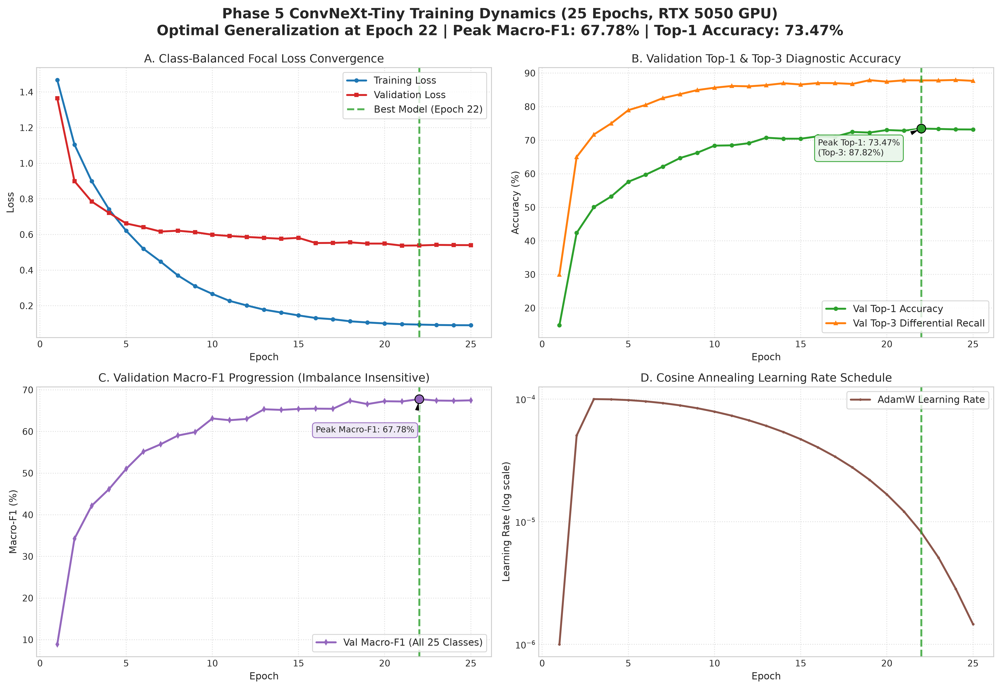

In [5]:
# ==============================================================================
# CELL 5: VISUALIZING TRAINING DYNAMICS & CONVERGENCE DIAGNOSTICS
# ==============================================================================
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure clinical aesthetic styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 16,
    "lines.linewidth": 2.2
})

# Load metrics log
metrics_csv = os.path.join(logs_dir, "training_metrics.csv")
if not os.path.exists(metrics_csv):
    # Fallback to local Notebooks path if running with notebook working directory
    metrics_csv = os.path.join("Models", "logs", "convnext_tiny", "training_metrics.csv")

df_metrics = pd.read_csv(metrics_csv)
best_epoch = int(df_metrics.loc[df_metrics["is_best"], "epoch"].max())
best_f1 = df_metrics.loc[df_metrics["epoch"] == best_epoch, "val_macro_f1"].values[0]
best_acc = df_metrics.loc[df_metrics["epoch"] == best_epoch, "val_top1_acc"].values[0]

# Setup 2x2 multi-panel diagnostic figure
fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=300)

epochs = df_metrics["epoch"]

# ------------------------------------------------------------------------------
# Panel 1: Loss Progression (Cross-Entropy / Focal Loss)
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
ax1.plot(epochs, df_metrics["train_loss"], label="Training Loss", color="#1f77b4", marker="o", markersize=4)
ax1.plot(epochs, df_metrics["val_loss"], label="Validation Loss", color="#d62728", marker="s", markersize=4)
ax1.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8, label=f"Best Model (Epoch {best_epoch})")
ax1.set_title("A. Class-Balanced Focal Loss Convergence")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel 2: Diagnostic Accuracy (Top-1 vs. Top-3 Differential Recall)
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
ax2.plot(epochs, df_metrics["val_top1_acc"], label="Val Top-1 Accuracy", color="#2ca02c", marker="o", markersize=4)
ax2.plot(epochs, df_metrics["val_top3_acc"], label="Val Top-3 Differential Recall", color="#ff7f0e", marker="^", markersize=4)
ax2.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8)
ax2.scatter([best_epoch], [best_acc], color="#2ca02c", s=100, zorder=5, edgecolors="black")
ax2.annotate(
    f"Peak Top-1: {best_acc:.2f}%\n(Top-3: {df_metrics.loc[df_metrics['epoch']==best_epoch, 'val_top3_acc'].values[0]:.2f}%)",
    xy=(best_epoch, best_acc),
    xytext=(best_epoch - 6, best_acc - 8),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    bbox=dict(boxstyle="round,pad=0.4", fc="#e8f5e9", ec="#2ca02c", alpha=0.9),
    fontsize=9.5
)
ax2.set_title("B. Validation Top-1 & Top-3 Diagnostic Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend(loc="lower right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel 3: Balanced Generalization Metric (25-Class Macro-F1)
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
ax3.plot(epochs, df_metrics["val_macro_f1"], label="Val Macro-F1 (All 25 Classes)", color="#9467bd", marker="d", markersize=4)
ax3.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8)
ax3.scatter([best_epoch], [best_f1], color="#9467bd", s=100, zorder=5, edgecolors="black")
ax3.annotate(
    f"Peak Macro-F1: {best_f1:.2f}%",
    xy=(best_epoch, best_f1),
    xytext=(best_epoch - 6, best_f1 - 8),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    bbox=dict(boxstyle="round,pad=0.4", fc="#ede7f6", ec="#9467bd", alpha=0.9),
    fontsize=9.5
)
ax3.set_title("C. Validation Macro-F1 Progression (Imbalance Insensitive)")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Macro-F1 (%)")
ax3.legend(loc="lower right", frameon=True)
ax3.grid(True, linestyle=":", alpha=0.6)

# ------------------------------------------------------------------------------
# Panel 4: Learning Rate Dynamics (Linear Warmup -> Cosine Decay)
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
ax4.plot(epochs, df_metrics["learning_rate"], label="AdamW Learning Rate", color="#8c564b", marker=".", markersize=4)
ax4.axvline(x=best_epoch, color="#2ca02c", linestyle="--", alpha=0.8)
ax4.set_yscale("log")
ax4.set_title("D. Cosine Annealing Learning Rate Schedule")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate (log scale)")
ax4.legend(loc="upper right", frameon=True)
ax4.grid(True, linestyle=":", alpha=0.6)

# Suptitle and formatting
plt.suptitle(
    "Phase 5 ConvNeXt-Tiny Training Dynamics (25 Epochs, RTX 5050 GPU)\n"
    f"Optimal Generalization at Epoch {best_epoch} | Peak Macro-F1: {best_f1:.2f}% | Top-1 Accuracy: {best_acc:.2f}%",
    y=0.99,
    fontweight="bold"
)

plt.tight_layout()

# Save high-resolution plot for report and thesis
plots_dir = os.path.join(PROJECT_ROOT, "results", "plots", "convnext_training")
os.makedirs(plots_dir, exist_ok=True)
plot_save_path = os.path.join(plots_dir, "01_convnext_tiny_training_curves.png")
plt.savefig(plot_save_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Training Dynamics Plot Successfully Generated & Saved:")
print(f"  --> {plot_save_path}")
print("=" * 80)

  EVALUATING BEST CONVNEXT-TINY ON STRICTLY ISOLATED TEST HOLDOUT
Loading optimal checkpoint: C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\Models\checkpoints\convnext_tiny\best_convnext_tiny.pth
✓ Successfully Loaded Best Model (Trained to Epoch 22 | Val Macro-F1: 67.78%)
Running batch inference across 4,599 test images on cuda...
--------------------------------------------------------------------------------
✓ Test Holdout Evaluation Complete (N = 4,599 images):
    - Test Loss                  : 0.5452
    - Test Top-1 Accuracy        : 73.47%
    - Test Top-3 Accuracy        : 87.61%
    - Test Macro-F1 (Balanced)   : 68.20%
    - Test Weighted-F1           : 73.32%
--------------------------------------------------------------------------------
CLINICAL ACUITY TIER AUDIT:
  • Tier 1 (N = 1,317): Accuracy = 67.73% | Macro-F1 = 25.53%
  • Tier 2 (N = 3,282): Accuracy = 75.78% | Macro-F1 = 49.91%

✓ Saved Full Classification Report to:

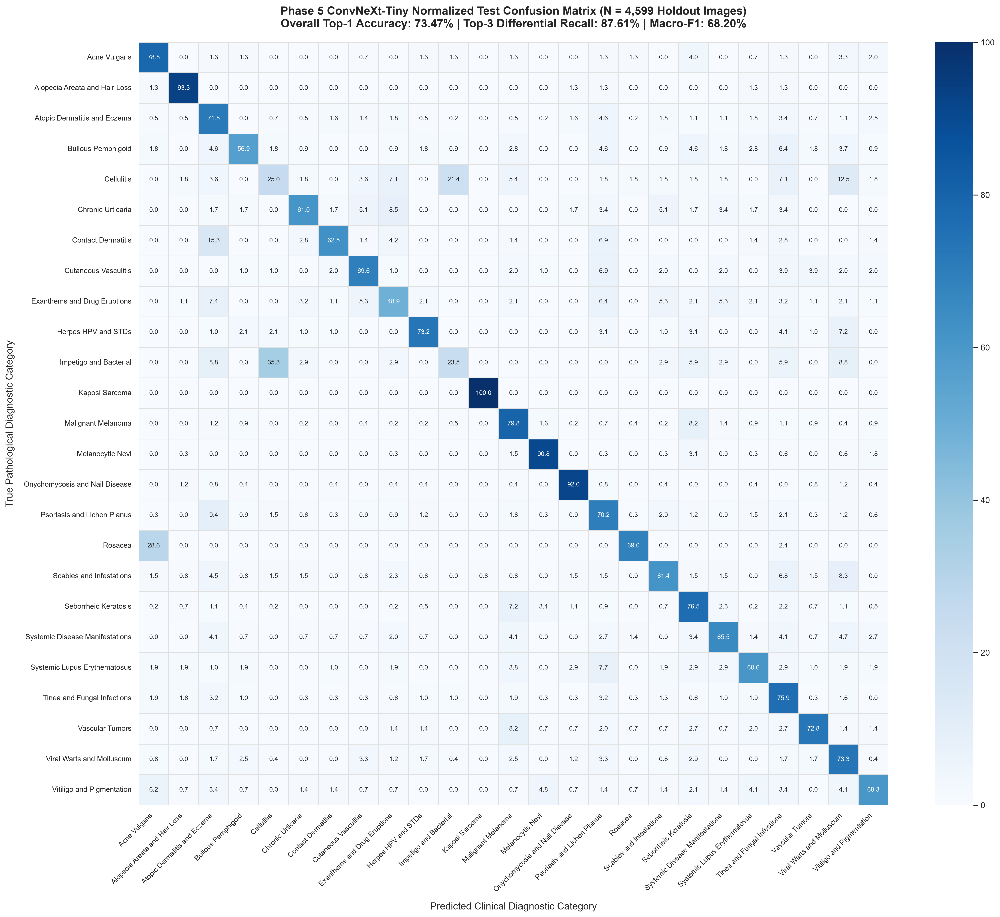

✓ Test Confusion Matrix Successfully Generated & Saved:
  --> C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project\results\plots\convnext_training\02_convnext_tiny_test_confusion_matrix.png
PHASE 5 COMPLETE: Ready to proceed to documentation and Phase 6 (Swin Transformer)!


In [8]:
# ==============================================================================
# CELL 6: UNBIASED EVALUATION ON ISOLATED TEST HOLDOUT (4,599 SAMPLES)
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

print("=" * 80)
print("  EVALUATING BEST CONVNEXT-TINY ON STRICTLY ISOLATED TEST HOLDOUT")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1. Resolve Root Path & Clinical Tier Mapping
# ------------------------------------------------------------------------------
PROJECT_ROOT = CONFIG.get(
    "project_root", 
    r"C:\Users\kvcsu_ht23nk8\OneDrive\Desktop\all_Projects\BTech_Project\skin-disease\BTech_Project"
)

test_manifest_path = os.path.join(PROJECT_ROOT, "metadata", "splits", "test_manifest.csv")
if os.path.exists(test_manifest_path):
    df_meta = pd.read_csv(test_manifest_path)
    CLASS_TIERS = dict(zip(df_meta["unified_class"], df_meta["clinical_tier"]))
else:
    # Explicit Fallback Mapping
    CLASS_TIERS = {
        "Kaposi_Sarcoma": "Tier 1", "Malignant_Melanoma": "Tier 1", "Bullous_Pemphigoid": "Tier 1",
        "Cellulitis": "Tier 1", "Cutaneous_Vasculitis": "Tier 1", "Systemic_Lupus_Erythematosus": "Tier 1",
        "Systemic_Disease_Manifestations": "Tier 1", "Exanthems_and_Drug_Eruptions": "Tier 1",
        "Scabies_and_Infestations": "Tier 1",
        "Acne_Vulgaris": "Tier 2", "Alopecia_Areata_and_Hair_Loss": "Tier 2", "Atopic_Dermatitis_and_Eczema": "Tier 2",
        "Chronic_Urticaria": "Tier 2", "Contact_Dermatitis": "Tier 2", "Herpes_HPV_and_STDs": "Tier 2",
        "Impetigo_and_Bacterial": "Tier 2", "Melanocytic_Nevi": "Tier 2", "Onychomycosis_and_Nail_Disease": "Tier 2",
        "Psoriasis_and_Lichen_Planus": "Tier 2", "Rosacea": "Tier 2", "Seborrheic_Keratosis": "Tier 2",
        "Tinea_and_Fungal_Infections": "Tier 2", "Vascular_Tumors": "Tier 2", "Viral_Warts_and_Molluscum": "Tier 2",
        "Vitiligo_and_Pigmentation": "Tier 2"
    }

# ------------------------------------------------------------------------------
# 2. Load Best Saved Checkpoint Weights
# ------------------------------------------------------------------------------
print(f"Loading optimal checkpoint: {best_model_path}")
checkpoint = torch.load(best_model_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

best_epoch = checkpoint.get("best_epoch", checkpoint.get("epoch", "N/A"))
best_val_f1 = checkpoint.get("best_val_f1", 0.0)
print(f"✓ Successfully Loaded Best Model (Trained to Epoch {best_epoch} | Val Macro-F1: {best_val_f1:.2f}%)")

# ------------------------------------------------------------------------------
# 3. Forward Inference Over Test Holdout Set
# ------------------------------------------------------------------------------
test_loss = 0.0
test_samples = 0
all_test_preds = []
all_test_targets = []
all_test_probs = []
top3_correct = 0

print(f"Running batch inference across {len(test_loader.dataset):,} test images on {DEVICE}...")

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast("cuda", enabled=CONFIG["mixed_precision"]):
            logits = model(imgs)
            loss = criterion(logits, labels)

        batch_size = labels.size(0)
        test_loss += loss.item() * batch_size
        test_samples += batch_size

        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_test_preds.extend(preds.cpu().numpy())
        all_test_targets.extend(labels.cpu().numpy())
        all_test_probs.extend(probs.cpu().numpy())

        # Top-3 Differential Accuracy
        _, top3_indices = torch.topk(logits, k=3, dim=1)
        top3_correct += (top3_indices == labels.unsqueeze(1)).any(dim=1).sum().item()

avg_test_loss = test_loss / test_samples
all_test_preds = np.array(all_test_preds)
all_test_targets = np.array(all_test_targets)
all_test_probs = np.array(all_test_probs)

test_top1_acc = (all_test_preds == all_test_targets).mean() * 100.0
test_top3_acc = (top3_correct / test_samples) * 100.0
test_macro_f1 = f1_score(all_test_targets, all_test_preds, average="macro", zero_division=0) * 100.0
test_weighted_f1 = f1_score(all_test_targets, all_test_preds, average="weighted", zero_division=0) * 100.0

print("-" * 80)
print(f"✓ Test Holdout Evaluation Complete (N = {test_samples:,} images):")
print(f"    - Test Loss                  : {avg_test_loss:.4f}")
print(f"    - Test Top-1 Accuracy        : {test_top1_acc:.2f}%")
print(f"    - Test Top-3 Accuracy        : {test_top3_acc:.2f}%")
print(f"    - Test Macro-F1 (Balanced)   : {test_macro_f1:.2f}%")
print(f"    - Test Weighted-F1           : {test_weighted_f1:.2f}%")

# ------------------------------------------------------------------------------
# 4. Clinical Acuity Tier Stratified Performance
# ------------------------------------------------------------------------------
test_df = pd.DataFrame({
    "true_label": all_test_targets,
    "pred_label": all_test_preds,
    "correct": (all_test_preds == all_test_targets)
})
test_df["class_name"] = test_df["true_label"].map(ID_TO_LABEL)
test_df["tier"] = test_df["class_name"].map(CLASS_TIERS)

print("-" * 80)
print("CLINICAL ACUITY TIER AUDIT:")
tier_summary = []
for tier_name in sorted(test_df["tier"].dropna().unique()):
    tier_subset = test_df[test_df["tier"] == tier_name]
    t_acc = tier_subset["correct"].mean() * 100.0
    t_f1 = f1_score(tier_subset["true_label"], tier_subset["pred_label"], average="macro", zero_division=0) * 100.0
    print(f"  • {tier_name} (N = {len(tier_subset):,}): Accuracy = {t_acc:.2f}% | Macro-F1 = {t_f1:.2f}%")
    tier_summary.append({"Tier": tier_name, "Samples": len(tier_subset), "Accuracy": round(t_acc, 2), "Macro_F1": round(t_f1, 2)})

# ------------------------------------------------------------------------------
# 5. Generate & Save Per-Class Classification Report
# ------------------------------------------------------------------------------
target_names = [ID_TO_LABEL[i] for i in range(CONFIG["num_classes"])]
report_dict = classification_report(
    all_test_targets, 
    all_test_preds, 
    target_names=target_names, 
    output_dict=True, 
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()
df_report["Tier"] = df_report.index.map(lambda x: CLASS_TIERS.get(x, ""))

report_save_path = os.path.join(logs_dir, "test_classification_report.csv")
df_report.to_csv(report_save_path)
print(f"\n✓ Saved Full Classification Report to: {report_save_path}")

# Preview Critical High-Risk Conditions
critical_classes = ["Malignant_Melanoma", "Bullous_Pemphigoid", "Cellulitis", "Kaposi_Sarcoma", "Cutaneous_Vasculitis"]
preview_df = df_report.loc[[c for c in critical_classes if c in df_report.index], ["precision", "recall", "f1-score", "support"]]
print("\nCritical High-Risk Lesions Audit Preview:")
print(preview_df.round(3).to_string())

# ------------------------------------------------------------------------------
# 6. Normalized 25-Class Confusion Matrix Heatmap
# ------------------------------------------------------------------------------
cm = confusion_matrix(all_test_targets, all_test_preds, normalize="true") * 100.0
clean_display_names = [name.replace("_", " ") for name in target_names]

plots_dir = os.path.join(PROJECT_ROOT, "results", "plots", "convnext_training")
os.makedirs(plots_dir, exist_ok=True)
cm_plot_path = os.path.join(plots_dir, "02_convnext_tiny_test_confusion_matrix.png")

plt.figure(figsize=(20, 17), dpi=300)
sns.set_theme(style="white")

ax = sns.heatmap(
    cm, 
    annot=True, 
    fmt=".1f", 
    cmap="Blues", 
    cbar=True,
    xticklabels=clean_display_names, 
    yticklabels=clean_display_names,
    annot_kws={"size": 8.5},
    linewidths=0.5,
    linecolor="#e0e0e0"
)

plt.title(
    f"Phase 5 ConvNeXt-Tiny Normalized Test Confusion Matrix (N = {test_samples:,} Holdout Images)\n"
    f"Overall Top-1 Accuracy: {test_top1_acc:.2f}% | Top-3 Differential Recall: {test_top3_acc:.2f}% | Macro-F1: {test_macro_f1:.2f}%",
    fontsize=15, 
    pad=20, 
    fontweight="bold"
)
plt.xlabel("Predicted Clinical Diagnostic Category", fontsize=13, labelpad=12)
plt.ylabel("True Pathological Diagnostic Category", fontsize=13, labelpad=12)
plt.xticks(rotation=45, ha="right", fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)

plt.tight_layout()
plt.savefig(cm_plot_path, bbox_inches="tight")
plt.show()

print("=" * 80)
print(f"✓ Test Confusion Matrix Successfully Generated & Saved:")
print(f"  --> {cm_plot_path}")
print("=" * 80)
print("PHASE 5 COMPLETE: Ready to proceed to documentation and Phase 6 (Swin Transformer)!")